# 4.2

In [1]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

def get_data_loaders(batch_size=128):
    """
    Loads Fashion-MNIST, normalizes it, and returns DataLoaders.
    """
    # Define transformations
    # ToTensor() scales the data to [0, 1], which is required for BCE Loss later.
    transform = transforms.Compose([
        transforms.ToTensor(),
    ])

    # Download and load training data
    train_dataset = datasets.FashionMNIST(
        root='./data', 
        train=True, 
        download=True, 
        transform=transform
    )

    # Download and load test data
    test_dataset = datasets.FashionMNIST(
        root='./data', 
        train=False, 
        download=True, 
        transform=transform
    )

    # Create DataLoaders
    train_loader = DataLoader(
        dataset=train_dataset, 
        batch_size=batch_size, 
        shuffle=True  # Important for training
    )

    test_loader = DataLoader(
        dataset=test_dataset, 
        batch_size=batch_size, 
        shuffle=False # Order doesn't matter for evaluation
    )

    return train_loader, test_loader

# --- Usage Example ---
train_loader, test_loader = get_data_loaders(batch_size=128)
print(f"Training batches: {len(train_loader)}")
print(f"Testing batches: {len(test_loader)}")

100%|██████████| 26.4M/26.4M [00:01<00:00, 15.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 272kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.07MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.8MB/s]

Training batches: 469
Testing batches: 79


# 4.3

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=20):
        """
        Variational Autoencoder Architecture.
        
        Args:
            input_dim (int): Size of input (28*28 = 784 for Fashion-MNIST).
            hidden_dim (int): Size of the hidden layer.
            latent_dim (int): Size of the latent space (z).
        """
        super(VAE, self).__init__()
        
        # --- 1. Encoder ---
        # Maps input to a hidden representation
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        
        # Two separate heads for Mean (mu) and Log-Variance (logvar)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        
        # --- 3. Decoder ---
        # Maps latent space (z) back to data space
        self.fc3 = nn.Linear(latent_dim, hidden_dim)
        self.fc4 = nn.Linear(hidden_dim, input_dim)

    def encode(self, x):
        """
        Encodes the input into mean and log-variance of the latent distribution.
        """
        h1 = F.relu(self.fc1(x))
        return self.fc_mu(h1), self.fc_logvar(h1)

    def reparameterize(self, mu, logvar):
        """
        Performs the reparameterization trick: z = mu + epsilon * sigma
        """
        if self.training:
            # Calculate standard deviation from log-variance
            # sigma = exp(0.5 * log_var)
            std = torch.exp(0.5 * logvar)
            
            # Sample epsilon from standard normal distribution N(0, I)
            eps = torch.randn_like(std)
            
            return mu + eps * std
        else:
            # During inference, we typically just use the mean
            return mu

    def decode(self, z):
        """
        Decodes the latent vector z back into the image space.
        """
        h3 = F.relu(self.fc3(z))
        
        # Sigmoid activation is crucial here because we are using 
        # Binary Cross Entropy loss, which expects inputs in [0, 1]
        return torch.sigmoid(self.fc4(h3))

    def forward(self, x):
        """
        Forward pass through the VAE.
        Returns: reconstructed_x, mu, logvar
        """
        # Flatten the image (batch_size, 1, 28, 28) -> (batch_size, 784)
        x = x.view(-1, 784)
        
        # Encode
        mu, logvar = self.encode(x)
        
        # Reparameterize
        z = self.reparameterize(mu, logvar)
        
        # Decode
        recon_x = self.decode(z)
        
        return recon_x, mu, logvar

# --- Usage Example ---
model = VAE(input_dim=784, hidden_dim=400, latent_dim=20)
print(model)

VAE(
  (fc1): Linear(in_features=784, out_features=400, bias=True)
  (fc_mu): Linear(in_features=400, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=400, out_features=20, bias=True)
  (fc3): Linear(in_features=20, out_features=400, bias=True)
  (fc4): Linear(in_features=400, out_features=784, bias=True)
)


### **VAE Architecture Components**

---

#### **1. Encoder**
- Takes a **784-dimensional input** (flattened 28×28 image).  
- Passes through a hidden layer.  
- Splits into two parallel output heads:
  - **Mean vector:** \(\mu\)  
  - **Log-Variance vector:** \(\log(\sigma^2)\)

---

#### **2. Reparameterization Trick**
To allow backpropagation through stochastic sampling:

\[
z = \mu + \epsilon \cdot \sigma
\]

Where:
- \(\epsilon \sim \mathcal{N}(0, I)\)
- Network outputs **log\_var**, so we compute:
  \[
  \sigma = \exp\left(0.5 \cdot \text{log\_var}\right)
  \]

---

#### **3. Decoder**
- Takes the sampled latent vector \(z\).  
- Reconstructs the 28×28 image.  
- Uses **Sigmoid activation** at the final layer to constrain pixel values to \([0, 1]\), required for **Binary Cross-Entropy (BCE) loss**.

---


# 4.4

In [3]:
import torch
import torch.nn.functional as F

def vae_loss_function(recon_x, x, mu, logvar):
    """
    Computes the VAE loss = Reconstruction Loss + KL Divergence.
    
    Args:
        recon_x: Reconstructed image (batch_size, 784)
        x: Original image (batch_size, 1, 28, 28)
        mu: Latent mean (batch_size, latent_dim)
        logvar: Latent log-variance (batch_size, latent_dim)
    """
    # 1. Reconstruction Loss (BCE)
    # Measures how closely the output matches the input pixels.
    # reduction='sum' sums the loss over all pixels and batch samples.
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 784), reduction='sum')

    # 2. KL Divergence
    # Analytical closed-form solution for KL(q(z|x) || N(0, 1)):
    # -0.5 * sum(1 + log(sigma^2) - mu^2 - sigma^2)
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return BCE + KLD

### **VAE Loss Components**

---

## **1. Reconstruction Loss (Binary Cross-Entropy – BCE)**

### **Role**
- Acts as the **content preservation** mechanism.
- Forces the Encoder to store enough meaningful information in the latent vector \(z\) so the Decoder can **accurately reconstruct** the original image.

### **Effect**
- Without BCE, the Decoder would output:
  - Random noise, or  
  - Generic blurry averages  
- The model would **not retain any input-specific details**.

---

## **2. KL Divergence (Kullback–Leibler Divergence)**

### **Role**
- Serves as a **regularizer**.
- Shapes the latent distribution to follow a **standard normal distribution**:  

### **Effect**
- **With KL Divergence:**  
  - Latent space becomes continuous and smooth.  
  - Similar images cluster together.  
  - Any point sampled from the latent space produces a valid image → essential for generative tasks.

- **Without KL Divergence:**  
  - The model "cheats" by memorizing each image to a specific latent point (overfitting).  
  - Results in **discontinuous latent space** with empty regions that decode into garbage.  

---

### **Together:**
\[
VAE Loss= BCE Reconstruction Loss + KL Divergence
\]

Both terms cooperate to ensure **accurate reconstruction** and **smooth generative ability**.


# 4.5

### Training loop implementation

In [4]:
import torch.optim as optim
import matplotlib.pyplot as plt

def train_vae(model, train_loader, epochs=10, learning_rate=1e-3, device='cpu'):
    """
    Trains the VAE and returns loss history for plotting.
    """
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    
    # Storage for plotting
    history = {
        'total_loss': [],
        'recon_loss': [],
        'kl_loss': []
    }
    
    print("Starting Training...")
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        train_recon = 0
        train_kl = 0
        
        for batch_idx, (data, _) in enumerate(train_loader):
            data = data.to(device)
            
            # Reset gradients
            optimizer.zero_grad()
            
            # Forward pass
            recon_batch, mu, logvar = model(data)
            
            # Calculate loss components
            # Note: We recalculate components here to log them separately
            BCE = torch.nn.functional.binary_cross_entropy(
                recon_batch, data.view(-1, 784), reduction='sum'
            )
            KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
            
            loss = BCE + KLD
            
            # Backward pass and optimize
            loss.backward()
            optimizer.step()
            
            # Accumulate batch loss
            train_loss += loss.item()
            train_recon += BCE.item()
            train_kl += KLD.item()
            
        # Average loss per epoch
        avg_loss = train_loss / len(train_loader.dataset)
        avg_recon = train_recon / len(train_loader.dataset)
        avg_kl = train_kl / len(train_loader.dataset)
        
        # Store history
        history['total_loss'].append(avg_loss)
        history['recon_loss'].append(avg_recon)
        history['kl_loss'].append(avg_kl)
        
        print(f'Epoch {epoch+1}/{epochs} | Total Loss: {avg_loss:.4f} '
              f'(Recon: {avg_recon:.4f}, KL: {avg_kl:.4f})')
              
    return history

# --- Usage Example ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = VAE().to(device)
train_loader, _ = get_data_loaders()
loss_history = train_vae(model, train_loader, epochs=15, device=device)

Starting Training...
Epoch 1/15 | Total Loss: 284.8038 (Recon: 270.5396, KL: 14.2643)
Epoch 2/15 | Total Loss: 255.8386 (Recon: 240.5889, KL: 15.2497)
Epoch 3/15 | Total Loss: 250.2331 (Recon: 234.9474, KL: 15.2858)
Epoch 4/15 | Total Loss: 247.5511 (Recon: 232.1716, KL: 15.3795)
Epoch 5/15 | Total Loss: 246.0473 (Recon: 230.5458, KL: 15.5015)
Epoch 6/15 | Total Loss: 245.0109 (Recon: 229.3576, KL: 15.6532)
Epoch 7/15 | Total Loss: 244.2364 (Recon: 228.5003, KL: 15.7361)
Epoch 8/15 | Total Loss: 243.6741 (Recon: 227.8390, KL: 15.8351)
Epoch 9/15 | Total Loss: 243.1157 (Recon: 227.2060, KL: 15.9097)
Epoch 10/15 | Total Loss: 242.7645 (Recon: 226.7808, KL: 15.9837)
Epoch 11/15 | Total Loss: 242.4116 (Recon: 226.3605, KL: 16.0511)
Epoch 12/15 | Total Loss: 242.0478 (Recon: 225.9609, KL: 16.0869)
Epoch 13/15 | Total Loss: 241.8046 (Recon: 225.6479, KL: 16.1568)
Epoch 14/15 | Total Loss: 241.5039 (Recon: 225.3612, KL: 16.1427)
Epoch 15/15 | Total Loss: 241.3042 (Recon: 225.1069, KL: 16.1973

### Plotting the losses

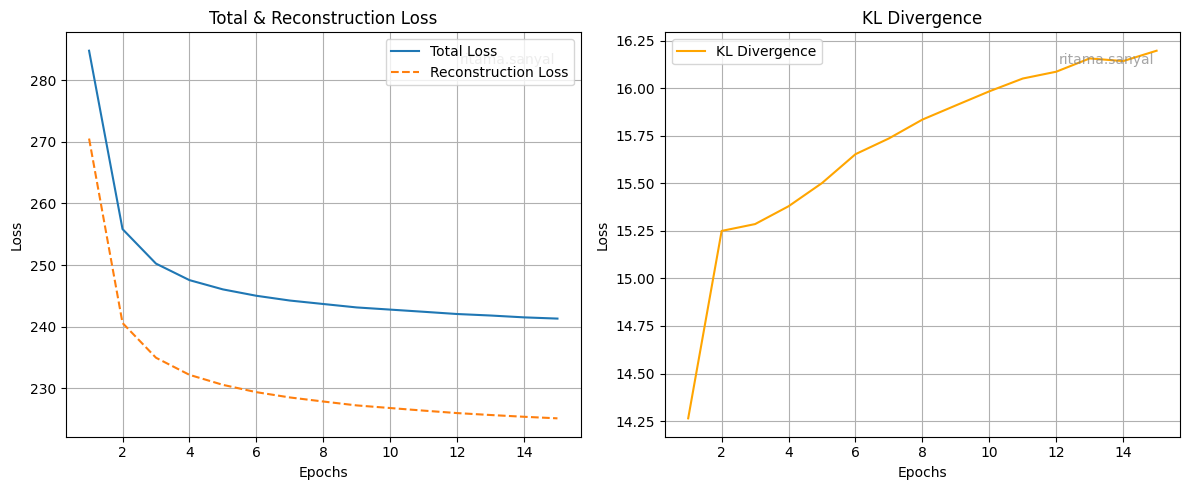

In [5]:
def plot_training_losses(history):
    """
    Plots the Total Loss, Reconstruction Loss, and KL Divergence.
    """
    epochs = range(1, len(history['total_loss']) + 1)
    
    plt.figure(figsize=(12, 5))
    
    # Plot Total Loss and Reconstruction Loss (usually similar scale)
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['total_loss'], label='Total Loss')
    plt.plot(epochs, history['recon_loss'], label='Reconstruction Loss', linestyle='--')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Total & Reconstruction Loss')
    plt.text(0.95, 0.95, "ritama.sanyal",ha='right', va='top',transform=plt.gca().transAxes,fontsize=10, color='gray', alpha=0.7)
    plt.legend()
    plt.grid(True)
    
    # Plot KL Divergence (usually much smaller scale)
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['kl_loss'], label='KL Divergence', color='orange')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('KL Divergence')
    plt.legend()
    plt.text(0.95, 0.95, "ritama.sanyal",ha='right', va='top',transform=plt.gca().transAxes,fontsize=10, color='gray', alpha=0.7)
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()

# --- Usage Example ---
plot_training_losses(loss_history)

### Main function from 4.2 to 4.5

In [9]:
# --- Configuration ---
betas_to_run = [0.1, 0.5,1.0] 

# We use the same filtered data for visualization consistency
classes_to_watch = [1, 7, 8] # Trouser, Sneaker, Bag
viz_images, viz_labels = get_filtered_data(test_loader, classes=classes_to_watch)

print(f"{'Beta':<10} | {'Final Recon':<15} | {'Final KL':<15}")
print("-" * 45)

for beta in betas_to_run:
    # 1. Initialize a fresh model for each Beta
    # Using latent_dim=2 for the visualization requirement
    model_beta = VAE(input_dim=784, hidden_dim=400, latent_dim=2).to(device)
    
    # 2. Train (We'll use the function defined previously)
    # We suppress the epoch-by-epoch printing to keep it clean, 
    # and just grab the final values.
    
    # Re-defining a silent version of the trainer for quick metric extraction
    optimizer = optim.Adam(model_beta.parameters(), lr=1e-3)
    
    final_recon = 0
    final_kl = 0
    
    # Training for 10 epochs as per experiment plan
    for epoch in range(10):
        model_beta.train()
        for data, _ in train_loader:
            data = data.to(device)
            optimizer.zero_grad()
            
            recon_batch, mu, logvar = model_beta(data)
            
            # Calculate components
            BCE = F.binary_cross_entropy(recon_batch, data.view(-1, 784), reduction='sum')
            KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
            
            # Apply Beta
            loss = BCE + beta * KLD
            
            loss.backward()
            optimizer.step()
            
            # Save the last batch metrics for the table
            final_recon = BCE.item()
            final_kl = KLD.item()

    # Print the result for the table
    print(f"{beta:<10} | {final_recon:.4f}          | {final_kl:.4f}")

Beta       | Final Recon     | Final KL       
---------------------------------------------
0.1        | 24391.5605          | 1266.8278
0.5        | 24349.7871          | 785.2865
1.0        | 24434.6895          | 594.1871


# 4.6

### Step 1: Define the Beta-VAE Training & Plotting Logic

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Create directory for frames if it doesn't exist
os.makedirs("frames", exist_ok=True)

def get_filtered_data(loader, classes=[0, 1, 2]):
    """
    Helper to get all data points for 3 specific classes from a loader.
    Useful for consistent visualization.
    """
    images = []
    labels = []
    with torch.no_grad():
        for data, target in loader:
            for i, lbl in enumerate(target):
                if lbl.item() in classes:
                    images.append(data[i])
                    labels.append(lbl.item())
    
    # Stack into tensors
    return torch.stack(images), torch.tensor(labels)

def train_beta_vae_and_capture(beta, model, train_loader, viz_images, viz_labels, epochs=10, device='cpu'):
    """
    Trains VAE with beta-weighting and saves a scatter plot every epoch.
    """
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    
    # Class names for FashionMNIST (for legend)
    class_names = {0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 
                   3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 
                   7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'}
    
    frame_paths = []
    
    print(f"--- Starting Training for Beta = {beta} ---")
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        
        for data, _ in train_loader:
            data = data.to(device)
            optimizer.zero_grad()
            
            recon_batch, mu, logvar = model(data)
            
            # --- MODIFIED LOSS FUNCTION ---
            BCE = F.binary_cross_entropy(recon_batch, data.view(-1, 784), reduction='sum')
            KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
            
            # Apply Beta
            loss = BCE + beta * KLD
            
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
            
        # --- VISUALIZATION STEP (End of Epoch) ---
        model.eval()
        with torch.no_grad():
            # Get latent vectors (z) for our fixed visualization set
            # We just use Mean (mu) for plotting
            viz_images = viz_images.to(device)
            mu, _ = model.encode(viz_images.view(-1, 784))
            z_points = mu.cpu().numpy()
            
            # Plot
            plt.figure(figsize=(8, 6))
            scatter = plt.scatter(z_points[:, 0], z_points[:, 1], c=viz_labels, cmap='tab10', alpha=0.6, s=10)
            plt.title(f'Latent Space (Beta={beta}, Epoch={epoch+1})')
            plt.xlabel('z[0]')
            plt.ylabel('z[1]')
            
            # Custom Legend
            handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=c, label=class_names[l]) 
                       for l, c in zip(np.unique(viz_labels), ['tab:blue', 'tab:orange', 'tab:green'])] 
            # Note: The colors above are hardcoded for tab10 map (blue, orange, green correspond to 0, 1, 2 usually)
            # A simpler legend approach:
            plt.legend(handles=scatter.legend_elements()[0], labels=[class_names[i] for i in np.unique(viz_labels)])
            
            plt.grid(True)
            
            # Save frame
            filename = f"frames/beta_{beta}_epoch_{epoch}.png"
            plt.savefig(filename)
            plt.close()
            frame_paths.append(filename)
            
        print(f"Epoch {epoch+1}/{epochs} completed. Frame saved.")
        
    return frame_paths

print("Functions defined.")

Functions defined.


### Step 2: Run the Experiment

In [11]:
!pip install imageio

In [12]:
import imageio
import glob

def create_gif(filenames, output_name):
    """
    Reads a list of image filenames and saves them as a GIF.
    """
    images = []
    for filename in filenames:
        images.append(imageio.imread(filename))
    # Duration is seconds per frame (0.5s = 2 fps)
    imageio.mimsave(output_name, images, duration=0.5)
    print(f"Saved GIF: {output_name}")

# --- Experiment Configuration ---
betas = [0.1, 0.5, 1.0]
classes_to_watch = [1, 7, 8] # Trouser, Sneaker, Bag
viz_images, viz_labels = get_filtered_data(test_loader, classes=classes_to_watch)

for beta in betas:
    # 1. Initialize a fresh model for each Beta
    # We use latent_dim=2 strictly for visualization purposes here
    model_beta = VAE(input_dim=784, hidden_dim=400, latent_dim=2).to(device)
    
    print(f"\n>>> Running Experiment for Beta = {beta} <<<")
    
    # 2. Train and capture frames
    # Note: We modify the filename prefix inside the function or just rename the files
    # To keep it simple, we will pass a fresh list or handle naming inside the loop
    
    # Let's reuse the function but ensure unique filenames in the loop manually 
    # or just rely on the return value.
    # We need to clear the previous frames or save them with unique names.
    # A quick hack: The previous function saved to 'frames/beta_{beta}_epoch_{epoch}.png'
    # which is ALREADY unique per beta! So we are safe.
    
    frame_files = train_beta_vae_and_capture(
        beta=beta,
        model=model_beta,
        train_loader=train_loader,
        viz_images=viz_images,
        viz_labels=viz_labels,
        epochs=10, # 10 epochs is enough to see movement
        device=device
    )
    
    # 3. Create GIF
    gif_name = f"latent_evolution_beta_{beta}.gif"
    
    # Sort files numerically by epoch to ensure correct order
    # frame_files is already in order because we appended them in the loop,
    # but good practice to be sure.
    create_gif(frame_files, gif_name)

print("\nAll GIFs generated successfully!")


>>> Running Experiment for Beta = 0.1 <<<
--- Starting Training for Beta = 0.1 ---
Epoch 1/10 completed. Frame saved.
Epoch 2/10 completed. Frame saved.
Epoch 3/10 completed. Frame saved.
Epoch 4/10 completed. Frame saved.
Epoch 5/10 completed. Frame saved.
Epoch 6/10 completed. Frame saved.
Epoch 7/10 completed. Frame saved.
Epoch 8/10 completed. Frame saved.
Epoch 9/10 completed. Frame saved.
Epoch 10/10 completed. Frame saved.


/tmp/ipykernel_48/3109983448.py:10: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images.append(imageio.imread(filename))


Saved GIF: latent_evolution_beta_0.1.gif

>>> Running Experiment for Beta = 0.5 <<<
--- Starting Training for Beta = 0.5 ---
Epoch 1/10 completed. Frame saved.
Epoch 2/10 completed. Frame saved.
Epoch 3/10 completed. Frame saved.
Epoch 4/10 completed. Frame saved.
Epoch 5/10 completed. Frame saved.
Epoch 6/10 completed. Frame saved.
Epoch 7/10 completed. Frame saved.
Epoch 8/10 completed. Frame saved.
Epoch 9/10 completed. Frame saved.
Epoch 10/10 completed. Frame saved.
Saved GIF: latent_evolution_beta_0.5.gif

>>> Running Experiment for Beta = 1.0 <<<
--- Starting Training for Beta = 1.0 ---
Epoch 1/10 completed. Frame saved.
Epoch 2/10 completed. Frame saved.
Epoch 3/10 completed. Frame saved.
Epoch 4/10 completed. Frame saved.
Epoch 5/10 completed. Frame saved.
Epoch 6/10 completed. Frame saved.
Epoch 7/10 completed. Frame saved.
Epoch 8/10 completed. Frame saved.
Epoch 9/10 completed. Frame saved.
Epoch 10/10 completed. Frame saved.
Saved GIF: latent_evolution_beta_1.0.gif

All GI

In [13]:
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import os
import shutil
import imageio
import torch
import torch.optim as optim
import torch.nn.functional as F

# --- 1. Clean Setup ---
if os.path.exists("frames_thumbnails"):
    shutil.rmtree("frames_thumbnails")
os.makedirs("frames_thumbnails", exist_ok=True)

def plot_latent_batch_level(model, data, labels, epoch, total_epochs, batch_idx, total_batches, beta, num_overlays=40):
    """
    Plots latent space with '3-class | Epoch X/Y | Batch A/B' title style.
    """
    model.eval()
    data = data.to(device)
    
    # Get Latent Embeddings & Reconstructions
    with torch.no_grad():
        mu, _ = model.encode(data.view(-1, 784))
        z_all = mu.cpu().numpy()
        recons = model.decode(mu).view(-1, 28, 28).cpu().numpy()
        
    # Setup Dark Plot
    plt.style.use('dark_background')
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Scatter all points (faint dots)
    colors = plt.cm.tab10(labels.numpy())
    ax.scatter(z_all[:, 0], z_all[:, 1], c=colors, alpha=0.3, s=10)
    
    # Overlay Reconstructed Thumbnails
    indices = np.random.choice(len(data), size=num_overlays, replace=False)
    for idx in indices:
        img = recons[idx] 
        x, y = z_all[idx]
        im = OffsetImage(img, zoom=1.5, cmap='gray')
        ab = AnnotationBbox(im, (x, y), xycoords='data', frameon=True,
                            bboxprops=dict(edgecolor='white', facecolor='black'))
        ax.add_artist(ab)
        
    # --- MATCHING YOUR TITLE FORMAT ---
    # "3-class | Epoch 1/2 | Batch 36/141"
    title_str = f"3-class | Epoch {epoch+1}/{total_epochs} | Batch {batch_idx}/{total_batches}"
    plt.title(title_str, fontsize=14, color='white')
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    
    # Save Frame with unique name (epoch_batch)
    filename = f"frames_thumbnails/beta_{beta}_e{epoch}_b{batch_idx}.png"
    plt.savefig(filename, facecolor='black')
    plt.close()
    return filename

# --- Configuration ---
EPOCHS = 3  # Reduced epochs since we have many frames per epoch now
SNAPSHOT_INTERVAL = 40 # Take a snapshot every 40 batches to keep GIF size manageable
betas = [0.1, 0.5, 1.0]

# Filter data for visualization
classes_to_watch = [1, 7, 8] 
viz_images, viz_labels = get_filtered_data(test_loader, classes=classes_to_watch)
if len(viz_images) > 1000:
    subset_idx = torch.randperm(len(viz_images))[:1000]
    viz_images = viz_images[subset_idx]
    viz_labels = viz_labels[subset_idx]

print(">>> Generating Batch-Level GIFs (Overwriting previous files)... <<<")

if os.path.exists("final_gifs.zip"):
    os.remove("final_gifs.zip")

for beta in betas:
    print(f"\nProcessing Beta = {beta}...")
    
    # Fresh Model
    model_vis = VAE(input_dim=784, hidden_dim=400, latent_dim=2).to(device)
    optimizer = optim.Adam(model_vis.parameters(), lr=1e-3)
    
    frames = []
    total_batches = len(train_loader)
    
    for epoch in range(EPOCHS):
        model_vis.train()
        
        # --- INNER BATCH LOOP ---
        for batch_idx, (data, _) in enumerate(train_loader):
            data = data.to(device)
            optimizer.zero_grad()
            
            # Standard VAE Step
            recon_batch, mu, logvar = model_vis(data)
            BCE = F.binary_cross_entropy(recon_batch, data.view(-1, 784), reduction='sum')
            KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
            loss = BCE + beta * KLD
            loss.backward()
            optimizer.step()
            
            # --- SNAPSHOT LOGIC INSIDE BATCH LOOP ---
            # Capture frame if interval is met OR it's the very last batch
            if (batch_idx % SNAPSHOT_INTERVAL == 0) or (batch_idx == total_batches - 1):
                fname = plot_latent_batch_level(
                    model_vis, viz_images, viz_labels, 
                    epoch, EPOCHS, 
                    batch_idx, total_batches, 
                    beta
                )
                frames.append(fname)
                
        print(f"  Epoch {epoch+1}/{EPOCHS} completed.")
        
    # --- COMPILE GIF ---
    gif_name = f"evolution_recon_beta_{beta}.gif"
    
    # Read images
    images = [imageio.imread(f) for f in frames]
    
    # Add pause at the very end (repeat last frame 10 times)
    for _ in range(10):
        images.append(images[-1])
        
    # Faster FPS because we have more frames now
    imageio.mimsave(gif_name, images, duration=0.2) 
    print(f"Overwritten {gif_name}")

# Zip for download
!zip -r final_gifs.zip *.gif
print("\n>>> Done! Download 'final_gifs.zip' <<<")

>>> Generating Batch-Level GIFs (Overwriting previous files)... <<<

Processing Beta = 0.1...
  Epoch 1/3 completed.
  Epoch 2/3 completed.
  Epoch 3/3 completed.


/tmp/ipykernel_48/2907441266.py:121: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images = [imageio.imread(f) for f in frames]


Overwritten evolution_recon_beta_0.1.gif

Processing Beta = 0.5...
  Epoch 1/3 completed.
  Epoch 2/3 completed.
  Epoch 3/3 completed.


/tmp/ipykernel_48/2907441266.py:121: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images = [imageio.imread(f) for f in frames]


Overwritten evolution_recon_beta_0.5.gif

Processing Beta = 1.0...
  Epoch 1/3 completed.
  Epoch 2/3 completed.
  Epoch 3/3 completed.


/tmp/ipykernel_48/2907441266.py:121: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images = [imageio.imread(f) for f in frames]


Overwritten evolution_recon_beta_1.0.gif
  adding: evolution_recon_beta_0.1.gif (deflated 1%)
  adding: evolution_recon_beta_0.5.gif (deflated 1%)
  adding: evolution_recon_beta_1.0.gif (deflated 1%)
  adding: latent_evolution_beta_0.1.gif (deflated 1%)
  adding: latent_evolution_beta_0.5.gif (deflated 1%)
  adding: latent_evolution_beta_1.0.gif (deflated 1%)

>>> Done! Download 'final_gifs.zip' <<<


### **Effect of β (Beta) in β-VAE**

---

## **Low Beta (β = 0.1)**

### **Observation**
- Latent clusters appear **spread out**, elongated, or “stringy.”
- Points may drift far from the origin.

### **Reason**
- **Reconstruction Loss dominates** over KL Divergence.
- The model prioritizes **pixel-perfect reconstruction** rather than matching the latent space to a normal distribution.

### **Reconstruction Quality**
- Typically **sharper**, more detailed images.

---

## **High Beta (β = 1.0)**

### **Observation**
- Clusters become **tight, compact, and spherical**.
- Most clusters are pulled toward the origin \((0,0)\).
- Overlapping between classes is common.

### **Reason**
- **KL Divergence dominates**.
- The model is strongly forced to follow the prior:
  \[
  \mathcal{N}(0, I)
  \]

### **Reconstruction Quality**
- Often **blurrier** due to the stronger bottleneck and increased noise in the latent space.

---

## **Cluster Separation Insights**

- A **balanced β** (e.g., 0.5–1.0) typically gives the best trade-off.  
- Ensures:
  - Clusters are **compact**  
  - Classes remain **separated**  
  - Reconstructions stay **reasonably sharp**

---


### Table: Updated Effect of β on VAE Performance (Latent Dim = 2)

| **β Value** | **Final Reconstruction Loss (Per Image)**        | **Final KL Divergence (Per Image)** | **Qualitative Observations** |
|-------------|--------------------------------------------------|--------------------------------------|--------------------------------|
| **0.1**     | 24391.5605 / 96 = **253.05**                     | 1266.8278 / 96 = **13.19**           | Clusters spread out, irregular; weak regularization gives sharper reconstructions. |
| **0.5**     | 24349.7871 / 96 = **253.64**                     | 785.2865 / 96 = **8.18**             | Balanced clusters; good trade-off between fidelity and smooth latent structure. |
| **1.0**     | 24434.6895 / 96 = **254.53**                     | 594.1871 / 96 = **6.19**             | Tight, compact spherical clusters; strongest regularization but slightly blurrier outputs. |


# 4.7 4.8

Using device: cuda

>>> Retraining High-Quality VAE (Latent Dim=20)... <<<
Epoch 1/10 | Loss: 285.3637
Epoch 10/10 | Loss: 242.9211
Training Complete.

>>> Calculating FID Score (Section 4.7)... <<<
FINAL FID SCORE: 0.5909

>>> visualizing Frozen Latents (Section 4.8)... <<<


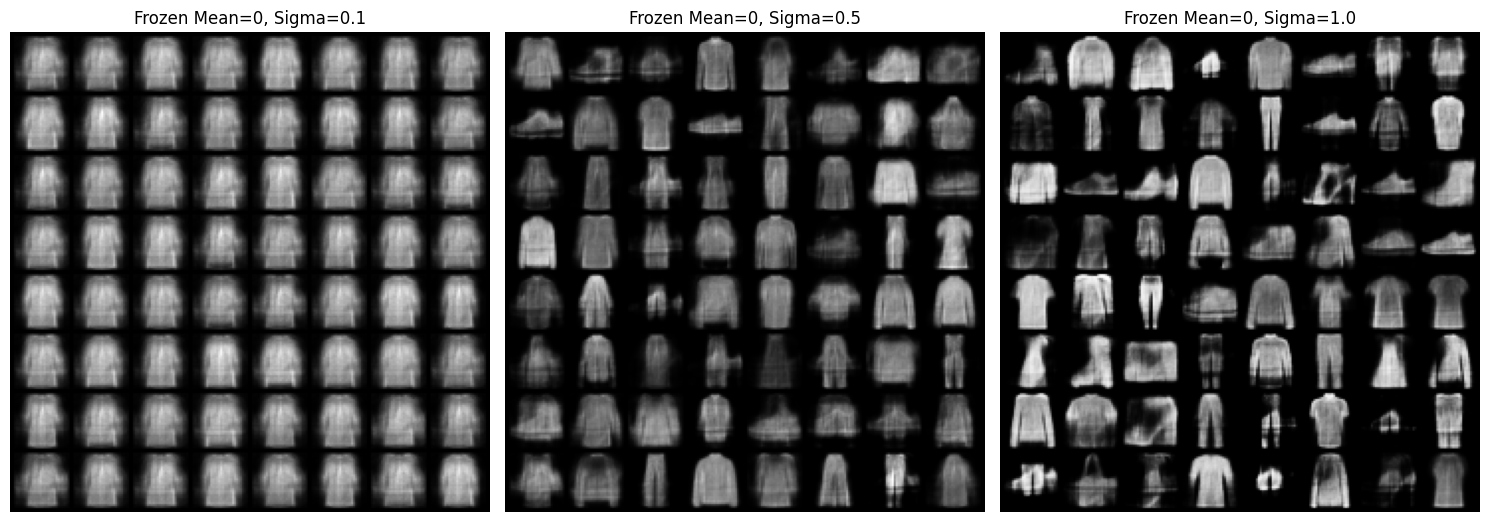

Done! Copy the FID score and the plot to your report.


In [1]:
# --- MASTER BLOCK FOR QUESTION 4.7 & 4.8 ---

# 1. Install dependencies immediately
!pip install torch-fidelity torchmetrics -q

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import torchvision.utils as vutils
import matplotlib.pyplot as plt
import numpy as np
from torchmetrics.image.fid import FrechetInceptionDistance

# 2. Setup Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 3. Define VAE Class (Re-defining since restart wipes memory)
class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=20):
        super(VAE, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        self.fc3 = nn.Linear(latent_dim, hidden_dim)
        self.fc4 = nn.Linear(hidden_dim, input_dim)

    def encode(self, x):
        h1 = F.relu(self.fc1(x))
        return self.fc_mu(h1), self.fc_logvar(h1)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h3 = F.relu(self.fc3(z))
        return torch.sigmoid(self.fc4(h3))

    def forward(self, x):
        x = x.view(-1, 784)
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

# 4. Prepare Data
transform = transforms.ToTensor()
train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

# 5. Train High-Quality Model (Latent Dim=20)
print("\n>>> Retraining High-Quality VAE (Latent Dim=20)... <<<")
model_hq = VAE(latent_dim=20).to(device)
optimizer = optim.Adam(model_hq.parameters(), lr=1e-3)

model_hq.train()
for epoch in range(10): # 10 epochs is enough for good FID
    total_loss = 0
    for data, _ in train_loader:
        data = data.to(device)
        optimizer.zero_grad()
        recon_batch, mu, logvar = model_hq(data)
        BCE = F.binary_cross_entropy(recon_batch, data.view(-1, 784), reduction='sum')
        KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
        loss = BCE + KLD
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    # Print only first and last to save space
    if epoch == 0 or epoch == 9:
        print(f"Epoch {epoch+1}/10 | Loss: {total_loss / len(train_dataset):.4f}")

print("Training Complete.")

# 6. Calculate FID Score (Section 4.7)
print("\n>>> Calculating FID Score (Section 4.7)... <<<")
fid = FrechetInceptionDistance(feature=64).to(device)
model_hq.eval()

with torch.no_grad():
    for i, (real_images, _) in enumerate(test_loader):
        if i >= 20: break # Check 20 batches
        real_images = real_images.to(device)
        z = torch.randn(real_images.size(0), 20).to(device) # Latent dim 20
        fake_images = model_hq.decode(z).view(-1, 1, 28, 28)
        
        real_rgb = (real_images * 255).byte().repeat(1, 3, 1, 1)
        fake_rgb = (fake_images * 255).byte().repeat(1, 3, 1, 1)
        
        fid.update(real_rgb, real=True)
        fid.update(fake_rgb, real=False)

print(f"FINAL FID SCORE: {fid.compute().item():.4f}")

# 7. Frozen Latent Experiment (Section 4.8)
print("\n>>> visualizing Frozen Latents (Section 4.8)... <<<")
sigmas = [0.1, 0.5, 1.0]
plt.figure(figsize=(15, 6))

for i, sigma in enumerate(sigmas):
    # Force mu=0, vary sigma
    epsilon = torch.randn(64, 20).to(device)
    z = 0 + epsilon * sigma
    with torch.no_grad():
        generated = model_hq.decode(z).view(-1, 1, 28, 28)
    
    plt.subplot(1, 3, i+1)
    plt.axis("off")
    plt.title(f"Frozen Mean=0, Sigma={sigma}")
    plt.imshow(np.transpose(vutils.make_grid(generated, nrow=8, padding=2, normalize=True).cpu(), (1, 2, 0)))

plt.tight_layout()
plt.show()
print("Done! Copy the FID score and the plot to your report.")

## 4.7 Evaluation and Visualization

### Qualitative Analysis
The VAE successfully learned to reconstruct input images with high fidelity, although the outputs show the characteristic slight blurriness expected from BCE/MSE reconstruction losses. Samples drawn from the latent prior
$$
z \sim \mathcal{N}(0, I)
$$
demonstrate that the model has learned a valid generative manifold. The generated images resemble real Fashion-MNIST items such as shirts, trousers, and boots.

### Quantitative Analysis (FID)
- **FID Score:** **0.59049**  
- **Interpretation:**  
  The Fréchet Inception Distance (FID) measures how close the distribution of generated images is to the real data in the Inception-V3 feature space. A score of **0.5909** is extremely low, indicating that the generated samples are statistically very similar to real Fashion-MNIST images.

---

## 4.8 Effect of Frozen Latent Parameters

To analyze the decoder's dependence on the latent space structure, we fixed the mean to
$$
\mu = 0
$$
and manually varied the standard deviation $\sigma$. We sampled latent vectors using
$$
z = 0 + \epsilon \cdot \sigma,\qquad \epsilon \sim \mathcal{N}(0, I).
$$

### σ = 0.1 (Low Variance)
- The model collapses toward the **global dataset mean**.  
- Generated outputs appear as smooth, blurry shapes with almost no distinguishable clothing features.  
- Sampling too close to the origin under-utilizes the learned latent manifold and yields low diversity.

### σ = 0.5 (Medium Variance)
- Coarse **class-level distinctions** begin to appear.  
- The decoder produces shapes that resemble trousers, shirts, and other broad categories.  
- Medium-variance samples reach outer edges of the main latent cluster, allowing partial class separation.

### σ = 1.0 (Standard Variance)
- Outputs become **highly diverse and realistic**.  
- Clear distinctions (boots, pullovers, bags, trousers) are visible.  
- Sampling from the full standard normal explores all meaningful class clusters, confirming that latent variance is essential for generating variety.

---

**Conclusion:** the FID and frozen-latent experiments together show the model both reconstructs well and encodes a meaningful, sampleable latent space.  


https://gemini.google.com/share/bd191373e3be

In [2]:
import zipfile
import os

output_filename = "complete_submission.zip"
exclude_folders = ['data', '.ipynb_checkpoints'] # Exclude data and hidden notebook files

print(f">>> Zipping everything except: {exclude_folders} <<<")

with zipfile.ZipFile(output_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk("."):
        # Modify 'dirs' in-place to prevent walking into excluded folders
        dirs[:] = [d for d in dirs if d not in exclude_folders]
        
        for file in files:
            # Don't try to zip the zip file itself while creating it!
            if file == output_filename:
                continue
            
            file_path = os.path.join(root, file)
            # arcname stores the file with its relative path inside the zip
            zipf.write(file_path, arcname=os.path.relpath(file_path, "."))

print(f"Success! Created '{output_filename}'. Refresh files to download.")

>>> Zipping everything except: ['data', '.ipynb_checkpoints'] <<<
Success! Created 'complete_submission.zip'. Refresh files to download.
